# 🌱 Lesson 2: Data Cleaning II: Inconsistent Records, Invalid Values & Outliers
**Phase 2 · Data Preprocessing & Feature Engineering** &nbsp;|&nbsp; ⏱ about 3 hours &nbsp;|&nbsp; 📚 Prerequisite: Lesson 01

> *An outlier isn't a number you dislike. It's a question: error, rare event or different population?*

## 🎯 By the end of this lesson you will be able to
- Standardise inconsistent text categories using normalisation, dictionaries and fuzzy matching.
- Define and apply domain **validity rules** (including sentinel codes and cross-field logic).
- Detect outliers with Z-score, IQR, MAD, group-wise rules and Isolation Forest.
- Choose between removing, capping, transforming and flagging outliers.
- Package all of it into one reusable `clean_farm()` function and save the cleaned dataset.

---

In [1]:
import sys
sys.path.append("../utils")            # lets us import course_utils.py and agri_prep.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from course_utils import *             # load_raw_farm, profile, setup_plots, ...

setup_plots()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
np.random.seed(42)

In [2]:
import re, difflib
raw = load_raw_farm()
df = raw.copy()

# --- catch up with Lesson 01 (types + duplicates). Same steps, now in a few lines. ---
df["fertilizer_kg_ha"] = pd.to_numeric(df["fertilizer_kg_ha"].str.extract(r"(\d+\.?\d*)", expand=False))
for c in ["planting_date", "harvest_date"]:
    df[c] = pd.to_datetime(df[c], format="mixed")
print("rows:", len(df))

rows: 2485


> We'll redo the Lesson 01 steps inside one function at the end. For now `df` has the right types but still contains messy spellings, impossible values and duplicates.

---
# Part 1 · Inconsistent records

## 1.1 The problem
Computers compare text *character by character*. To pandas, `'Maize'`, `'maize'`, `' Maize'` and `'Corn'` are four different crops. Let's count how bad it is:

In [3]:
print("Distinct crop spellings :", df["crop"].nunique(), "(real crops: 5)")
print("Distinct county spellings:", df["county"].nunique(), "(real counties: 10)")
print("Distinct irrigation codes:", df["irrigation"].nunique(), "(real states: 2)")
df["crop"].value_counts().head(12)

Distinct crop spellings : 27 (real crops: 5)
Distinct county spellings: 37 (real counties: 10)
Distinct irrigation codes: 10 (real states: 2)


crop
Maize           718
Beans           416
Potato          354
Wheat           220
Sorghum         214
maize            41
MAIZE            39
Maize            34
Irish potato     33
POTATO           32
 Maize           31
Bean             31
Name: count, dtype: int64

## 1.2 A four-step recipe for categorical clean-up

1. **Normalise**: strip whitespace, lower-case, remove punctuation.
2. **Map known synonyms**: `corn → maize` (no algorithm can guess that; *you* know).
3. **Fuzzy-match typos**: `sorgum → sorghum` (an algorithm *can* guess this).
4. **Flag the rest**: anything unmatched becomes NaN and gets *reported*, never silently kept.

### Step 1 & 2 on a toy example

In [4]:
toy = pd.Series(["Maize", " maize", "MAIZE.", "Corn", "Sorgum", "Cassava", None])

step1 = toy.str.strip().str.lower().str.replace(r"[^a-z]", "", regex=True)   # normalise
print(step1.tolist())

synonyms = {"corn": "Maize"}
valid = {"maize": "Maize", "sorghum": "Sorghum", **synonyms}
print(step1.map(valid).tolist())

['maize', 'maize', 'maize', 'corn', 'sorgum', 'cassava', nan]
['Maize', 'Maize', 'Maize', 'Maize', nan, nan, nan]


`Sorgum` (typo) and `Cassava` (not in our crop list) are still unmatched. A typo is *close* to a valid word; Cassava is not close to anything. Python's standard library has a tool for measuring closeness, `difflib`:

In [5]:
print(difflib.get_close_matches("sorgum", ["maize", "sorghum", "wheat"], n=1, cutoff=0.8))
print(difflib.get_close_matches("cassava", ["maize", "sorghum", "wheat"], n=1, cutoff=0.8))
print("similarity('sorgum','sorghum') =", round(difflib.SequenceMatcher(None, "sorgum", "sorghum").ratio(), 2))

['sorghum']
[]
similarity('sorgum','sorghum') = 0.92


`cutoff=0.8` means "at least 80% similar". Too low (0.5) and `wheat` could be matched to `beans`; too high (0.95) and real typos escape. Always **inspect what got matched** and what didn't.

### Wrap it in a reusable function
A function you write once and trust forever. Notice it *returns the unmatched values* so nothing is hidden:

In [6]:
def standardise(series, canonical, synonyms=None, cutoff=0.8):
    """Map messy labels onto a canonical list.

    1. normalise (lower-case, letters only)  2. synonyms  3. fuzzy match  4. unmatched -> NaN
    Returns (clean_series, array_of_unmatched_original_values).
    """
    norm = lambda x: re.sub(r"[^a-z]", "", str(x).lower())
    lookup = {norm(c): c for c in canonical}
    lookup.update({norm(k): v for k, v in (synonyms or {}).items()})
    keys = list(lookup)

    def one(x):
        if pd.isna(x):
            return np.nan
        k = norm(x)
        if k in lookup:
            return lookup[k]
        close = difflib.get_close_matches(k, keys, n=1, cutoff=cutoff)
        return lookup[close[0]] if close else np.nan

    cleaned = series.map(one)
    unmatched = series[cleaned.isna() & series.notna()].unique()
    return cleaned, unmatched


# test on the toy series first!
standardise(toy, ["Maize", "Sorghum"], synonyms={"corn": "Maize"})

(0      Maize
 1      Maize
 2      Maize
 3      Maize
 4    Sorghum
 5        NaN
 6        NaN
 dtype: str,
 <StringArray>
 ['Cassava']
 Length: 1, dtype: str)

Tested on 7 values where we know the answer: `Cassava` is reported as unmatched, `None` stays missing, all maize/sorghum variants are fixed. **Now we trust it** on the real columns:

In [7]:
CROPS    = ["Maize", "Beans", "Wheat", "Potato", "Sorghum"]
COUNTIES = ["Uasin Gishu", "Trans Nzoia", "Nakuru", "Kakamega", "Bungoma", "Meru", "Machakos", "Nyeri", "Kisii", "Kiambu"]
SOILS    = ["Loam", "Clay", "Sandy", "Silt", "Volcanic"]
PESTS    = ["Low", "Medium", "High"]

df["crop"],          bad_crop   = standardise(df["crop"], CROPS, {"corn": "Maize", "irish potato": "Potato"})
df["county"],        bad_county = standardise(df["county"], COUNTIES)
df["soil_type"],     bad_soil   = standardise(df["soil_type"], SOILS)
df["pest_pressure"], bad_pest   = standardise(df["pest_pressure"], PESTS, {"med": "Medium"})

print("Unmatched ->", dict(crop=list(bad_crop), county=list(bad_county), soil=list(bad_soil), pest=list(bad_pest)))
print("\nCrops now :", df["crop"].nunique(), "| counties:", df["county"].nunique(), "| soils:", df["soil_type"].nunique())
df["crop"].value_counts()

Unmatched -> {'crop': [], 'county': [], 'soil': [], 'pest': []}

Crops now : 5 | counties: 10 | soils: 5


crop
Maize      922
Beans      531
Potato     455
Wheat      296
Sorghum    281
Name: count, dtype: int64

Dozens of spellings collapsed into just 5 crops, and nothing was left unmatched. (If something *had* been, we'd now be looking at it, deciding whether to add a synonym.)

## 1.3 Boolean-like columns
`irrigation` mixes `Yes, Y, yes, TRUE, 1` and `No, N, no, FALSE, 0`. Define the vocabulary **explicitly**:

In [8]:
YES, NO = {"yes", "y", "true", "1"}, {"no", "n", "false", "0"}

def to_flag(series):
    k = series.astype(str).str.strip().str.lower()
    return k.map(lambda v: 1 if v in YES else 0 if v in NO else np.nan)

print("before:", sorted(df["irrigation"].unique()))
df["irrigation"] = to_flag(df["irrigation"])
print("after :", df["irrigation"].value_counts(dropna=False).to_dict())

before: ['0', '1', 'FALSE', 'N', 'No', 'TRUE', 'Y', 'Yes', 'no', 'yes']
after : {0: 1870, 1: 615}


## 1.4 Cross-field consistency
Sometimes every single value is valid but **two columns contradict each other**. Two checks:

**Check A: does `season` agree with the planting month?** Kenya's *long rains* are planted around March–May and the *short rains* around October–December.

In [9]:
df["plant_month"] = df["planting_date"].dt.month
pd.crosstab(df["season"].fillna("(missing)"), df["plant_month"])

plant_month,3,4,10,11
season,,,,
(missing),17,11,13,9
Long rains,623,600,0,0
Short rains,0,0,583,629


Beautiful: the two columns agree 100% (every Long-rains row is planted in March/April, every Short-rains row in October/November. That also means that for the ~2% of rows with a **missing season** we don't need to guess) we can *derive* it from the planting month. That is the best kind of imputation: a deterministic rule, no statistics, no leakage.

In [10]:
derived = np.where(df["plant_month"].isin([3, 4, 5]), "Long rains",
          np.where(df["plant_month"].isin([10, 11, 12]), "Short rains", None))
print("missing season before:", df["season"].isna().sum())
df["season"] = df["season"].fillna(pd.Series(derived, index=df.index))
print("missing season after :", df["season"].isna().sum())
df = df.drop(columns="plant_month")

missing season before: 50
missing season after : 0


**Check B: harvest must come after planting.** And how long should each crop take?

In [11]:
df["grow_days"] = (df["harvest_date"] - df["planting_date"]).dt.days
print("harvest before planting:", (df["grow_days"] < 0).sum(), "rows")
print("\nGrowing days by crop (excluding the impossible ones):")
df.loc[df["grow_days"] >= 0].groupby("crop")["grow_days"].agg(["min", "median", "max"])

harvest before planting: 15 rows

Growing days by crop (excluding the impossible ones):


,min,median,max
crop,,,
Beans,80,90.0,100
Maize,150,160.0,170
Potato,100,110.0,120
Sorghum,110,120.0,130
Wheat,120,130.0,140


Every crop has a tight window (beans ≈ 90 days, maize ≈ 160). The negative ones are the planted-in-2019/harvested-in-2018 timeline errors. We trust the planting date, so we'll blank the **harvest date** for those rows.

In [12]:
bad_dates = df["grow_days"] < 0
df.loc[bad_dates, "harvest_date"] = pd.NaT
df = df.drop(columns="grow_days")
print("harvest dates blanked:", bad_dates.sum())

harvest dates blanked: 15


---
# Part 2 · Invalid values

## 2.1 Invalid vs outlier vs rare-but-real
These three look similar and are *completely different problems*:

| | Example | Cause | Treatment |
|---|---|---|---|
| **Invalid** | pH = 99, rainfall = −200 | Impossible in reality → error or sentinel code | Set to NaN (or drop): *always* |
| **Outlier (error)** | yield ×10 because of a misplaced decimal | Data-entry mistake that is *technically possible* | Detect, investigate, usually fix/NaN |
| **Outlier (real)** | A 300-ha commercial farm | Genuine, rare | Keep (maybe cap, or transform) |

> **The golden rule:** *Domain knowledge defines invalid. Statistics only suggests outliers.* Ask an agronomist, not a histogram, whether pH 99 is possible.

## 2.2 Step 1: hunt for sentinel codes
People write `-999`, `99`, or `9999` to mean "unknown". Let's scan every numeric column for them:

In [13]:
SENTINELS = [-999, -99, 99, 999, 9999]
num_cols = df.select_dtypes("number").columns
hits = {c: int(df[c].isin(SENTINELS).sum()) for c in num_cols}
{k: v for k, v in hits.items() if v}

{'avg_temp_c': 5, 'soil_ph': 3, 'fertilizer_kg_ha': 20}

A sentinel scan gives **suspects, not verdicts**. Temperature `-999` and `99` °C: certainly sentinels. Soil pH `99`: impossible. But `fertilizer_kg_ha` shows 20 hits too, and 99 kg/ha of fertilizer is a perfectly ordinary amount! Only domain knowledge tells them apart, which is exactly why the next step is a *rule table per column*, not a blanket 'delete all 99s'.

## 2.3 Step 2: a *rule table* of plausible values
Each rule is a (min, max) pair we can defend to an agronomist. Writing rules as **data** (not scattered `if`s) means you can read, review and report them.

In [14]:
RULES = {   # column: (min, max)  plausible for East-African smallholder farms
    "soil_ph":             (3, 10),
    "rainfall_mm":         (50, 3000),      # seasonal total
    "avg_temp_c":          (-5, 40),
    "farm_size_ha":        (0.01, 1000),
    "nitrogen_ppm":        (0, 500),
    "phosphorus_ppm":      (0, 300),
    "potassium_ppm":       (0, 800),
    "organic_matter_pct":  (0, 30),
    "fertilizer_kg_ha":    (0, 1000),
    "market_price_ksh_kg": (1, 1000),
}
YIELD_MAX = {"Maize": 12, "Beans": 4, "Wheat": 10, "Potato": 45, "Sorghum": 9}   # t/ha, physical ceilings


def rule_report(data, rules):
    rows = []
    for col, (lo, hi) in rules.items():
        v = data[col]
        bad = (v < lo) | (v > hi)             # NaN compares False -> missing is not a "violation"
        rows.append({"column": col, "allowed": f"{lo} .. {hi}", "violations": int(bad.sum()),
                     "examples": sorted(v[bad].unique())[:4]})
    return pd.DataFrame(rows).set_index("column")

rule_report(df, RULES)

,allowed,violations,examples
column,,,
soil_ph,3 .. 10,10,"[-1.0, 0.0, 14.5, 99.0]"
rainfall_mm,50 .. 3000,7,[-317.0]
avg_temp_c,-5 .. 40,5,"[-999.0, 99.0]"
farm_size_ha,0.01 .. 1000,7,[0.0]
nitrogen_ppm,0 .. 500,0,[]
phosphorus_ppm,0 .. 300,0,[]
potassium_ppm,0 .. 800,0,[]
organic_matter_pct,0 .. 30,0,[]
fertilizer_kg_ha,0 .. 1000,7,"[1504.0, 2262.0, 2385.0, 2403.0]"


A tidy audit table. We found impossible pH values, sentinel temperatures (−999, 99), negative sizes, absurd fertilizer amounts (the 2,000+ kg/ha entries), and the table tells us exactly which rule caught what.

**Apply the rules**: out-of-range values become NaN (they become ordinary *missing* values for the imputer later):

In [15]:
def apply_rules(data, rules):
    data = data.copy()
    for col, (lo, hi) in rules.items():
        data[col] = data[col].where(data[col].between(lo, hi))     # outside -> NaN, NaN stays NaN
    return data

df = apply_rules(df, RULES)
print("violations remaining:", int(rule_report(df, RULES)["violations"].sum()))

violations remaining: 0


## 2.4 Step 3: the target gets special treatment
Yield is what we're predicting. An impossible target can't be "imputed": a model must not learn from a made-up answer. So: **drop** rows whose yield is non-positive or above the crop's physical ceiling (that includes the ×10 decimal-point errors).

In [16]:
ceiling = df["crop"].map(YIELD_MAX)
bad_yield = df["yield_t_ha"].isna() | (df["yield_t_ha"] <= 0) | (df["yield_t_ha"] > ceiling)
print("missing yield   :", df["yield_t_ha"].isna().sum())
print("impossible yield:", (bad_yield & df["yield_t_ha"].notna()).sum(), "(<= 0 or above crop ceiling)")
print(df.loc[bad_yield & df["yield_t_ha"].notna(), ["crop", "yield_t_ha"]].head(5).to_string())
df = df.loc[~bad_yield].copy()
print("rows left:", len(df))

missing yield   : 38
impossible yield: 37 (<= 0 or above crop ceiling)
       crop  yield_t_ha
65   Potato  113.300000
130   Maize   -1.968344
445   Beans    0.000000
447   Maize   -1.968344
487   Maize   -1.968344
rows left: 2410


---
# Part 3 · Outlier detection and treatment

After removing the *impossible*, what remains are the **merely unusual**. Our job: decide whether each is an error, a rare real event, or a member of another population.

## 3.1 Look first

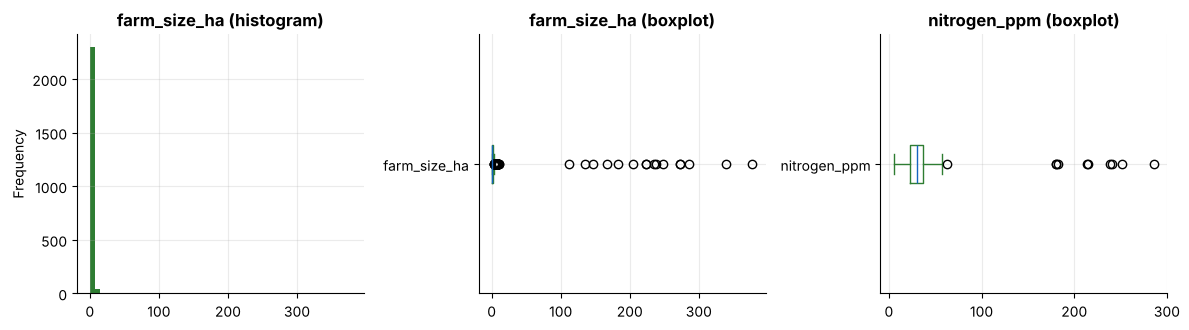

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
df["farm_size_ha"].plot.hist(bins=50, ax=ax[0], title="farm_size_ha (histogram)")
df["farm_size_ha"].plot.box(ax=ax[1], vert=False, title="farm_size_ha (boxplot)")
df["nitrogen_ppm"].plot.box(ax=ax[2], vert=False, title="nitrogen_ppm (boxplot)")
plt.tight_layout(); plt.show()

Farm size: a long right tail (a few huge farms). Nitrogen: a bunch of dots way off to the right of an otherwise tidy box. Different shapes → different stories.

## 3.2 Four detection methods

| Method | Rule | Strength | Weakness |
|---|---|---|---|
| **Z-score** | `|x−mean|/std > 3` | Simple, well known | Mean & std are distorted by the outliers; assumes bell shape |
| **IQR (Tukey)** | outside `Q1−1.5·IQR … Q3+1.5·IQR` | Robust, no distribution assumption | Flags many points in skewed data |
| **Modified z (MAD)** | `0.6745·|x−median|/MAD > 3.5` | Very robust | Less familiar |
| **Percentile** | below 1st / above 99th | Easy | *Always* flags 2% by construction, even if there are no outliers! |

### The mechanics on 10 numbers

In [18]:
x = pd.Series([4, 5, 5, 6, 6, 7, 7, 8, 8, 60.0])      # 60 is the obvious outlier

z = (x - x.mean()) / x.std()
q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
mad = (x - x.median()).abs().median()
mz = 0.6745 * (x - x.median()) / mad

pd.DataFrame({"x": x, "z": z.round(2), "IQR fence flag": (x < q1 - 1.5*iqr) | (x > q3 + 1.5*iqr), "modified z": mz.round(1)})

,x,z,IQR fence flag,modified z
0,4.0,-0.45,False,-1.1
1,5.0,-0.39,False,-0.7
2,5.0,-0.39,False,-0.7
3,6.0,-0.33,False,-0.2
4,6.0,-0.33,False,-0.2
5,7.0,-0.27,False,0.2
6,7.0,-0.27,False,0.2
7,8.0,-0.21,False,0.7
8,8.0,-0.21,False,0.7
9,60.0,2.84,True,24.1


Look at the `z` column: the outlier 60 has **z = 2.84**: *below* the usual cut-off of 3! The outlier inflated the standard deviation so much that it hid itself ("masking"). The IQR rule and the modified z (≈ 24) catch it instantly. That's why robust methods matter.

### On the real columns: all three side by side

In [19]:
def outlier_masks(s):
    s = s.dropna()
    z = (s - s.mean()) / s.std()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    mz = 0.6745 * (s - s.median()) / (s - s.median()).abs().median()
    return {"z>3": z.abs() > 3,
            "IQR 1.5x": (s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr),
            "IQR 3x (far out)": (s < q1 - 3*iqr) | (s > q3 + 3*iqr),
            "MAD>3.5": mz.abs() > 3.5}

cols = ["farm_size_ha", "fertilizer_kg_ha", "nitrogen_ppm", "rainfall_mm", "soil_ph"]
table = pd.DataFrame({c: {m: int(mask.sum()) for m, mask in outlier_masks(df[c]).items()} for c in cols}).T
table

,z>3,IQR 1.5x,IQR 3x (far out),MAD>3.5
farm_size_ha,16,167,79,171
fertilizer_kg_ha,2,2,0,0
nitrogen_ppm,9,10,9,9
rainfall_mm,0,3,0,0
soil_ph,4,17,0,0


Skewed columns (farm size, fertilizer) get many flags from the IQR rule (the tail is *naturally* long), while nearly-symmetric `rainfall_mm` and `soil_ph` get few. **The method must match the shape of the data.**

## 3.3 'Outlier relative to what?': group-wise detection
Yield differs enormously between crops (beans ≈ 1.5 t/ha, potato ≈ 15). Apply one global rule and we get nonsense:

In [20]:
def iqr_mask(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - k*i) | (s > q3 + k*i)

global_flag  = iqr_mask(df["yield_t_ha"])
by_crop_flag = df.groupby("crop")["yield_t_ha"].transform(iqr_mask).astype(bool)

compare = pd.DataFrame({"flagged by GLOBAL IQR": df.loc[global_flag, "crop"].value_counts(),
                        "flagged WITHIN each crop": df.loc[by_crop_flag, "crop"].value_counts()}).fillna(0).astype(int)
compare

,flagged by GLOBAL IQR,flagged WITHIN each crop
crop,,
Beans,0,5
Maize,1,3
Potato,198,3
Sorghum,0,25
Wheat,0,2


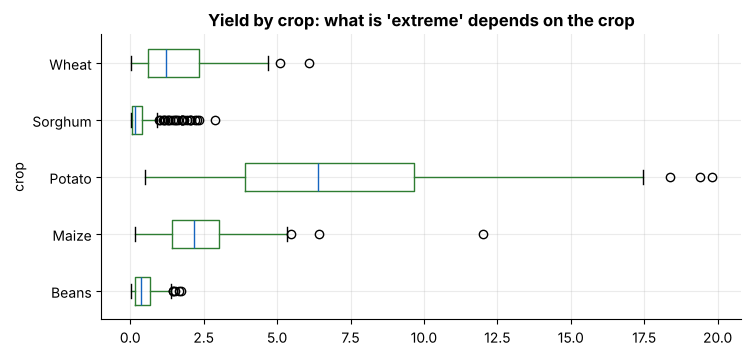

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.8))
df.boxplot(column="yield_t_ha", by="crop", ax=ax, vert=False)
ax.set_title("Yield by crop: what is 'extreme' depends on the crop"); plt.suptitle("")
plt.show()

Potatoes dominate the global flags: not because any potato farm is weird, but because potatoes live on a different scale. **Compare like with like.**

## 3.4 Multivariate outliers (a quick look)
A row can be fine in every column and still be strange as a *combination* (e.g. a desert rainfall with swamp-level yield). **Isolation Forest** isolates points that are easy to separate from the crowd:

In [22]:
from sklearn.ensemble import IsolationForest

feat = df[["rainfall_mm", "avg_temp_c", "soil_ph", "yield_t_ha"]].dropna()
iso = IsolationForest(contamination=0.01, random_state=0).fit(feat)
flag = iso.predict(feat) == -1
print("rows flagged:", flag.sum(), "of", len(feat))
feat[flag].head(6)

rows flagged: 21 of 2087


,rainfall_mm,avg_temp_c,soil_ph,yield_t_ha
85,556.6,18.0,6.33,16.64
109,619.7,15.4,6.36,17.46
123,413.5,15.6,6.25,14.67
136,378.7,14.7,5.29,6.35
191,569.4,16.4,6.15,17.20
382,1049.9,22.4,6.96,1.54


Isolation Forest is a *detector*, not a judge: it hands you suspects. Notice the rows with a yield of 15–17 t/ha: those are probably **potatoes**: perfectly healthy! The detector didn't know about crops. Context matters (add crop information, or detect within each crop). A human or a domain rule decides the verdict.

## 3.5 Treatment: what do we *do*?

| Option | When | Cost |
|---|---|---|
| **Remove the row** | Clear error, plenty of data, or the target itself | Loses information |
| **Set to NaN & impute** | Clear error in a *feature* | Needs a good imputation |
| **Cap / Winsorise** | Real but extreme, and your model is sensitive to magnitude | Distorts the tail |
| **Transform (log)** | Skewed data with a long real tail | Changes interpretation |
| **Keep + flag** | Real events that matter (e.g. commercial farms) | Model must be able to cope |
| **Use a robust model** | Trees barely care about outliers | None |

### Effect of treatments on a skewed column

In [23]:
s = df["farm_size_ha"].dropna()
q1, q3 = s.quantile([.25, .75]); upper = q3 + 1.5 * (q3 - q1)

versions = {
    "original": s,
    "outliers removed": s[s <= upper],
    f"capped at {upper:.1f} ha": s.clip(upper=upper),
    "log1p transform": np.log1p(s),
}
pd.DataFrame({k: {"mean": v.mean(), "std": v.std(), "skew": v.skew(), "max": v.max()} for k, v in versions.items()}).T.round(2)

,mean,std,skew,max
original,3.12,19.62,13.46,377.70
outliers removed,1.25,0.89,1.10,3.99
capped at 4.0 ha,1.45,1.11,1.07,4.00
log1p transform,0.85,0.60,3.41,5.94


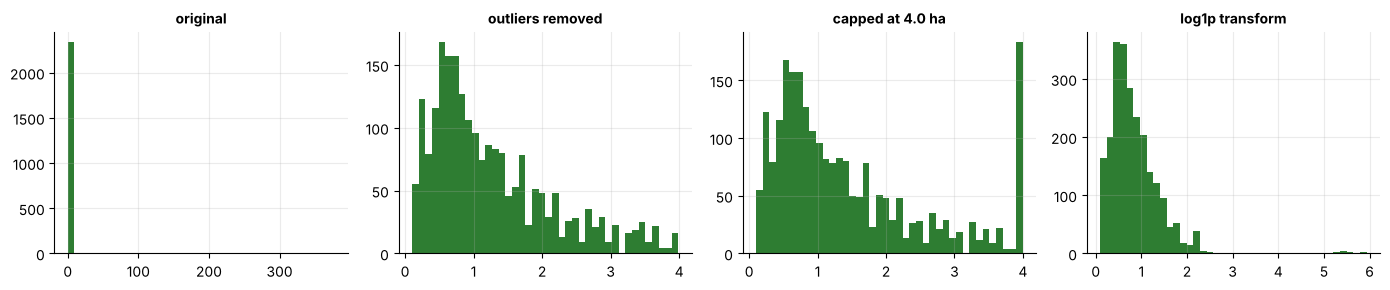

In [24]:
fig, ax = plt.subplots(1, 4, figsize=(14, 3), sharey=False)
for a, (name, v) in zip(ax, versions.items()):
    a.hist(v, bins=40); a.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

Skewness falls from ≈ 13 to ≈ 1 when we remove or cap the extremes. The log transform is more modest here (≈ 3.4): it compresses the long tail, but the 300-ha giants still stick out. Lesson: **log is not a magic wand**: extreme values may need capping *and* log. Every treatment changes what the column means, so pick the one that matches your story.

### 🔔 Important design decision: where does treatment happen?

Look at the cap above: `upper = Q3 + 1.5·IQR` is a **number learned from the data**. By our rule from Lesson 1, anything learned from data belongs **inside the training pipeline**: otherwise test data influences the cap. So in this course:

- **Domain rules** (pH ≤ 14, ceilings on yield) → applied *now*, structurally. No learning involved.
- **Statistical capping** (IQR fences, percentiles) → implemented as a `Winsorizer` *transformer* in Lesson 7, fitted on training data only.

In the next section we finalise the structural part.

---
# Part 4 · Putting it all together: `clean_farm()`

We've written the pieces. Now we **assemble them into one function**: the professional move. A function is:
- **repeatable** (run it on next year's raw file),
- **testable** (assertions below),
- **documentable** (it *is* the documentation of what we did).

In [25]:
def clean_farm(raw, verbose=True):
    """Structural cleaning of the raw farm records. Learns NOTHING from the data (no means, no medians)."""
    log = {"raw rows": len(raw)}
    df = raw.copy()

    # 1. types
    df["fertilizer_kg_ha"] = pd.to_numeric(df["fertilizer_kg_ha"].str.extract(r"(\d+\.?\d*)", expand=False))
    for c in ["planting_date", "harvest_date"]:
        df[c] = pd.to_datetime(df[c], format="mixed")

    # 2. inconsistent text -> canonical labels (BEFORE de-duplication!)
    df["crop"],          _ = standardise(df["crop"], CROPS, {"corn": "Maize", "irish potato": "Potato"})
    df["county"],        _ = standardise(df["county"], COUNTIES)
    df["soil_type"],     _ = standardise(df["soil_type"], SOILS)
    df["pest_pressure"], _ = standardise(df["pest_pressure"], PESTS, {"med": "Medium"})
    df["irrigation"] = to_flag(df["irrigation"])

    # 3. duplicates on the natural key, keeping the most complete record
    n = len(df)
    df = (df.assign(_n_missing=df.isna().sum(axis=1)).sort_values("_n_missing")
            .drop_duplicates(subset=["farm_id", "planting_date"], keep="first")
            .drop(columns="_n_missing").sort_index())
    log["duplicates removed"] = n - len(df)

    # 4. cross-field logic
    month = df["planting_date"].dt.month
    derived = np.where(month.isin([3, 4, 5]), "Long rains", np.where(month.isin([10, 11, 12]), "Short rains", None))
    df["season"] = df["season"].fillna(pd.Series(derived, index=df.index))
    bad_dates = df["harvest_date"] < df["planting_date"]
    log["harvest dates blanked"] = int(bad_dates.sum())
    df.loc[bad_dates, "harvest_date"] = pd.NaT

    # 5. invalid values -> NaN
    before_nan = int(df[list(RULES)].isna().sum().sum())
    df = apply_rules(df, RULES)
    log["feature values set to NaN (invalid)"] = int(df[list(RULES)].isna().sum().sum()) - before_nan

    # 6. the target: drop missing / impossible
    n = len(df)
    ceiling = df["crop"].map(YIELD_MAX)
    ok = df["yield_t_ha"].notna() & (df["yield_t_ha"] > 0) & (df["yield_t_ha"] <= ceiling)
    df = df.loc[ok].reset_index(drop=True)
    log["rows dropped (bad/missing target)"] = n - len(df)
    log["clean rows"] = len(df)

    if verbose:
        print("CLEANING LOG")
        for k, v in log.items():
            print(f"  {k:40s} {v:>6}")
    return df


clean = clean_farm(load_raw_farm())

CLEANING LOG
  raw rows                                   2485
  duplicates removed                           85
  harvest dates blanked                        14
  feature values set to NaN (invalid)          35
  rows dropped (bad/missing target)            71
  clean rows                                 2329


### ✅ Quality gate: assertions
A clean dataset should *prove* it is clean. If a future change breaks something, these checks will shout:

In [26]:
assert not clean.duplicated(subset=["farm_id", "planting_date"]).any(), "duplicates remain"
assert set(clean["crop"].unique()) <= set(CROPS)
assert set(clean["county"].unique()) <= set(COUNTIES)
assert set(clean["irrigation"].dropna().unique()) <= {0, 1}
assert clean["yield_t_ha"].between(0.01, 45).all()
assert clean["soil_ph"].dropna().between(3, 10).all()
assert clean["season"].notna().all()
assert (clean["harvest_date"].dropna() >= clean.loc[clean["harvest_date"].notna(), "planting_date"]).all()
print("✅ all quality checks passed")

✅ all quality checks passed


### Before vs after

In [27]:
raw = load_raw_farm()
pd.DataFrame({
    "raw":   {"rows": len(raw), "distinct crops": raw["crop"].nunique(), "distinct counties": raw["county"].nunique(),
              "text columns that should be numeric/date": 3, "exact+near duplicates": 85},
    "clean": {"rows": len(clean), "distinct crops": clean["crop"].nunique(), "distinct counties": clean["county"].nunique(),
              "text columns that should be numeric/date": 0, "exact+near duplicates": int(clean.duplicated(["farm_id", "planting_date"]).sum())},
})

,raw,clean
rows,2485,2329
distinct crops,27,5
distinct counties,37,10
text columns that should be numeric/date,3,0
exact+near duplicates,85,0


### 💾 Save for the next lessons
**Notice that missing values are still there.** Imputing them is a *statistical* step: it learns medians from data, so it belongs in the pipeline after the train/test split.

In [28]:
out_path = DATA / "farm_clean_lesson.csv"
clean.to_csv(out_path, index=False)
print("saved ->", out_path.name, clean.shape)
print("\nremaining NaNs (to be handled in the pipeline):")
clean.isna().sum()[lambda s: s > 0].sort_values(ascending=False).to_frame("n_missing").T

saved -> farm_clean_lesson.csv (2329, 22)

remaining NaNs (to be handled in the pipeline):


,fertilizer_kg_ha,organic_matter_pct,soil_ph,nitrogen_ppm,phosphorus_ppm,experience,potassium_ppm,rainfall_mm,pest_pressure,avg_temp_c,market_price_ksh_kg,soil_type,farm_size_ha,harvest_date
n_missing,320,163,148,119,119,116,116,101,95,76,71,70,51,11


---
## 🏁 Recap of Lesson 2
We turned **2,485 messy rows** into a structurally sound dataset by normalising text, validating values with explicit rules, resolving date logic and removing duplicates and impossible targets, and we *documented every decision in code*.

Next lesson: scaling, log transforms and categorical encoding: turning clean columns into numbers a model can digest.

---
## 🧩 Practice problems
Now it is your turn. Each problem is **self-contained** (it tells you what data to load), so you can do them in any order.

**How to work like a pro:**
1. Read the problem twice. Predict the answer *before* you code.
2. Struggle for at least 10 minutes. Struggling is where learning happens.
3. Open a **hint** only when stuck - they get progressively stronger.
4. Compare with `solutions/solutions_02.ipynb` **after** you have your own answer.

Difficulty: ⭐ warm-up · ⭐⭐ core skill · ⭐⭐⭐ challenge

### Problem 2.1 &nbsp; ⭐ &nbsp; Standardise soil types

In the raw data, `soil_type` has spellings such as `'loam'`, `'LOAM'`, `'Loamy'`, `'Sand'`, `'Silty'`. 
Standardise it to exactly the five valid labels: **Loam, Clay, Sandy, Silt, Volcanic** (missing values stay missing). Print `value_counts(dropna=False)` before and after.

<details><summary>💡 Hint 1</summary>

Start with `s.str.strip().str.lower()`.

</details>

<details><summary>💡💡 Hint 2</summary>

Some variants are not just case: `loamy`, `sand`, `silty`. Build a dictionary like `{'loamy': 'Loam', 'sand': 'Sandy', 'silty': 'Silt'}` for them.

</details>

<details><summary>💡💡💡 Hint 3</summary>

Or use `difflib.get_close_matches(word, valid_lowercase_labels, n=1, cutoff=0.8)` to match typos automatically. Always print what remains unmatched.

</details>

In [29]:
# ✏️ Your code here

### Problem 2.2 &nbsp; ⭐⭐ &nbsp; Turn 'Yes / Y / TRUE / 1' into 1 and 0

`irrigation` has values like `Yes, yes, Y, TRUE, 1, No, no, N, FALSE, 0`. Convert it to a clean 0/1 integer column. Verify nothing was left unmapped, and report the percentage of irrigated records.

<details><summary>💡 Hint 1</summary>

Lower-case and strip first, then check membership in two sets: `{'yes','y','true','1'}` and `{'no','n','false','0'}`.

</details>

<details><summary>💡💡 Hint 2</summary>

`k.map(lambda v: 1 if v in YES else 0 if v in NO else np.nan)`

</details>

<details><summary>💡💡💡 Hint 3</summary>

`out.isna().sum()` should be 0 (there are no missing irrigation values in this file).

</details>

In [30]:
# ✏️ Your code here

### Problem 2.3 &nbsp; ⭐⭐ &nbsp; Write a validity rule table

Define plausible bounds for `rainfall_mm` (50–3000), `avg_temp_c` (−5 to 40) and `soil_ph` (3–10). 

1. Report how many raw values violate each rule and show a few examples.
2. Which of these violations look like **sentinel codes** (-999, 99, ...)?

<details><summary>💡 Hint 1</summary>

Use `(s < lo) | (s > hi)` to create a violation mask. Remember NaN comparisons are False, so missing values are not 'violations'.

</details>

<details><summary>💡💡 Hint 2</summary>

Print `sorted(s[mask].unique())` to see the offending values.

</details>

<details><summary>💡💡💡 Hint 3</summary>

Sentinels are suspiciously round placeholder numbers such as -999, 99 or 9999.

</details>

In [31]:
# ✏️ Your code here

### Problem 2.4 &nbsp; ⭐⭐ &nbsp; Three outlier detectors, one column

For `nitrogen_ppm` (use only values > 0, drop NaN), count the outliers flagged by:
- **Z-score** (|z| > 3),
- **IQR / Tukey fences** (1.5 × IQR),
- **Modified z-score using the median and MAD** (> 3.5).

Which method flags the most? Which one is the *least robust* and why?

<details><summary>💡 Hint 1</summary>

z = (x − mean) / std.

</details>

<details><summary>💡💡 Hint 2</summary>

IQR fences: `Q1 − 1.5·IQR` and `Q3 + 1.5·IQR` with `IQR = Q3 − Q1`.

</details>

<details><summary>💡💡💡 Hint 3</summary>

Modified z = 0.6745 · (x − median) / MAD, where MAD = median(|x − median|). The classic z-score uses mean and std, which the outliers themselves distort.

</details>

In [32]:
# ✏️ Your code here

### Problem 2.5 &nbsp; ⭐⭐⭐ &nbsp; Outlier relative to what?

Load the lesson-clean data with `load_lesson_clean()` (finish notebook 02 first: it creates this file).

1. Flag `yield_t_ha` outliers with the IQR rule **globally**, and again **within each crop**.
2. Which crop produces most of the *global* flags? Is that crop actually behaving strangely?
3. Write one sentence on what this teaches about outlier detection.

<details><summary>💡 Hint 1</summary>

Write a small function `iqr_mask(s, k=1.5)` returning a boolean Series.

</details>

<details><summary>💡💡 Hint 2</summary>

Global: `iqr_mask(df['yield_t_ha'])`. Per crop: `df.groupby('crop')['yield_t_ha'].transform(iqr_mask)`.

</details>

<details><summary>💡💡💡 Hint 3</summary>

Compare `df[global_flag]['crop'].value_counts()` with `df[by_crop_flag]['crop'].value_counts()`.

</details>

In [33]:
# ✏️ Your code here

---
## ✅ Check your understanding
Answer in your head first, *then* click to reveal.

**Q1.** Which is *invalid* rather than merely an outlier?

- **A)** A 300-ha farm in a smallholder survey
- **B)** A soil pH of 99
- **C)** A very high maize yield
- **D)** A farm with 0 kg fertilizer

<details><summary>Show answer</summary>

**B**: pH is physically limited to 0–14. A value of 99 is impossible: an error or a sentinel code. The others are unusual but possible.

</details>

**Q2.** Why is the plain z-score a weak outlier detector for small, heavily contaminated data?

- **A)** It needs a normal distribution and mean/std are themselves pulled by the outliers
- **B)** It is too slow
- **C)** It only works for integers
- **D)** It cannot be computed in pandas

<details><summary>Show answer</summary>

**A**: Outliers inflate the mean and standard deviation, shrinking everyone's z: 'masking'. Median/MAD or IQR are robust.

</details>

**Q3.** You find a yield of 85 t/ha for beans (the plausible maximum is ~4). The best treatment?

- **A)** Keep and ignore
- **B)** Treat as invalid (misplaced decimal): remove the row or set to NaN
- **C)** Replace with the average of all crops
- **D)** Winsorise to the 95th percentile of potatoes

<details><summary>Show answer</summary>

**B**: An impossible value from a likely data-entry error should be removed or blanked, not 'preserved'. Domain knowledge beats statistics here.

</details>

**Q4.** Rows with the same farm and date but `crop='MAIZE'` vs `'Maize'` should be treated…

- **A)** As two different crops
- **B)** As one record typed twice: standardise, then de-duplicate
- **C)** As an error to ignore
- **D)** As a missing value

<details><summary>Show answer</summary>

**B**: Standardise *before* you compare. Cleaning steps depend on each other.

</details>

---
## 📌 Summary: what to remember
- Normalise → map synonyms → fuzzy match → flag leftovers. Always inspect unmatched values.
- Invalid ≠ outlier. Domain rules define invalid; statistics only suggests outliers.
- Write validity rules as a *table of data*, then report violations before changing anything.
- Z-score can be fooled by the outliers it is looking for. IQR and MAD are robust.
- Detect outliers within comparable groups (per crop).
- Rule-based fixes are structural (now). Anything with learned thresholds belongs in the pipeline.

## 🚧 Common mistakes
- ⚠️ Cleaning after splitting into train/test inconsistently (or learning thresholds from the full dataset).
- ⚠️ Fuzzy matching with too low a cutoff: silently merging different categories.
- ⚠️ Removing real extremes (large farms) just because they look odd.
- ⚠️ Ignoring cross-field consistency (harvest before planting).

➡️ **Next:** Lesson 03: Data Transformation: scaling, log transforms and encoding.